In [1]:
import numpy as np
import matplotlib.pyplot as plt

from dls.neural_net import predict, train
from dls.dataset import boston_train_test_split
from dls.model_error import mae, rmse

In [2]:
boston_ns = boston_train_test_split()
X_train, y_train, X_test, y_test, features = (
    boston_ns.X_train,
    boston_ns.y_train,
    boston_ns.X_test,
    boston_ns.y_test,
    boston_ns.features,
)


In [3]:
train_info = train(
    X_train,
    y_train,
    X_test,
    y_test,
    n_iter=10000,
    test_every=1000,
    learning_rate=0.001,
    batch_size=23,
    return_losses=True,
    return_weights=True,
    return_scores=False,
    seed=180807,
)
losses = train_info[0]
weights = train_info[1]


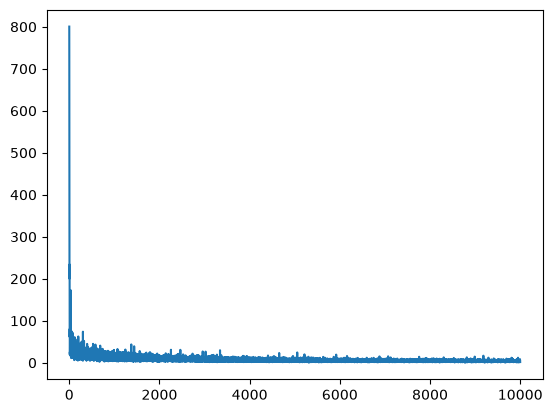

In [10]:
plt.plot(list(range(10000)), losses)


In [4]:
preds = predict(X_test, weights)
print(
    "Mean absolute error:",
    round(mae(preds, y_test), 4),
    "\nRoot mean squared error:",
    round(rmse(preds, y_test), 4),
)

Mean absolute error: 2.5951 
Root mean squared error: 3.8851


In [8]:
NUM = 40
a = np.repeat(X_test[:, :-1].mean(axis=0, keepdims=True), NUM, axis=0)
b = np.linspace(-1.5, 3.5, NUM).reshape(NUM, 1)

test_feature = np.concatenate([a, b], axis=1)
test_preds = predict(test_feature, weights)[:, 0]


Text(0.5, 1.0, 'Most important feature vs. target and predictions,\n custom linear regression')

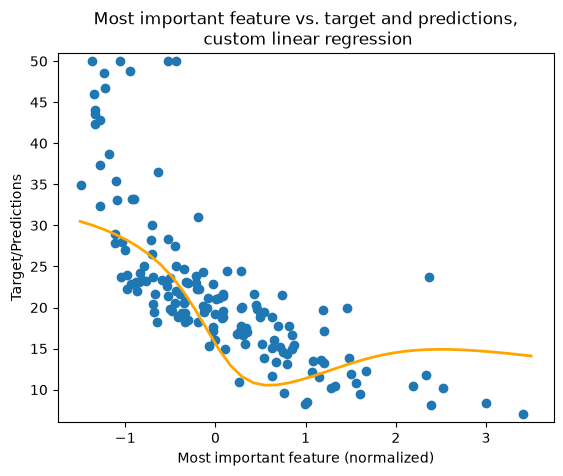

In [9]:
plt.scatter(X_test[:, 12], y_test)
plt.plot(np.array(test_feature[:, -1]), test_preds, linewidth=2, c="orange")
plt.ylim([6, 51])
plt.xlabel("Most important feature (normalized)")
plt.ylabel("Target/Predictions")
plt.title(
    "Most important feature vs. target and predictions,\n custom linear regression"
)
